# 07 - Logistic Regression

**Project:** DetectIt – Intelligent Web Threat Detection Using Machine Learning

**Goal:** Train and test Logistic Regression on the processed PhiUSIIL data (Experiment 1), compare different feature sets, and test the URL-only version on the external dataset (Experiment 2).

**About the model:** Logistic Regression gives each feature a weight. It adds up the weighted features and turns the total into a probability between 0 and 1. If the probability is above 0.5, the URL is called phishing. It is a simple and fast model, and it is a good baseline to compare the other models with. It needs scaling, so we use the shared scaling pipeline.

**Input:** `data/processed/`

**Output:** `results/metrics/`, `results/confusion_matrices/`, `results/feature_importance/`

## Setup

We load the libraries and the shared functions from `src/`. Every team member uses the same functions, so all results are calculated in the same way and can be compared fairly.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression

sys.path.append(str(Path("..").resolve()))
from src.data import get_feature_sets, load_train_test, load_url_experiment, sample_rows
from src.evaluation import (
    RANDOM_STATE,
    cross_validate_model,
    evaluate_model,
    make_cv,
    make_scaled_pipeline,
    plot_confusion_matrix,
    save_results,
)

In [2]:
X_train, X_test, y_train, y_test = load_train_test()
feature_sets = get_feature_sets()

print(f"Training set: {X_train.shape[0]:,} rows | {X_train.shape[1]} features")
print(f"Test set:     {X_test.shape[0]:,} rows | {X_test.shape[1]} features")

Training set: 188,296 rows | 69 features
Test set:     47,074 rows | 69 features


## Model Settings

`C` controls how strict the model is. A small `C` keeps the weights small and the model simple. A large `C` lets the model follow the training data more closely. We try 4 values. Logistic Regression is fast, so we tune on the full training set.

In [3]:
MODEL_NAME = "Logistic Regression"
model = make_scaled_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))

param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10],
}

TUNING_SAMPLE_SIZE = None

## 1. Hyperparameter Tuning

We try each combination of settings in `param_grid` using 3-fold cross-validation on the training set, and keep the one with the best F1-score. The test set is not used here.

In [4]:
X_tune, y_tune = sample_rows(X_train, y_train, TUNING_SAMPLE_SIZE)

search = GridSearchCV(model, param_grid, scoring="f1", cv=make_cv(3), n_jobs=-1)
search.fit(X_tune, y_tune)
best_model = search.best_estimator_

print(f"Best settings: {search.best_params_}")
print(f"Best cross-validation F1: {search.best_score_:.4f}")

Best settings: {'logisticregression__C': 10}
Best cross-validation F1: 0.9999


## 2. Cross-Validation

We check the best model with 5-fold stratified cross-validation. The mean shows the usual score, and the standard deviation (Std) shows how stable the model is. A small Std means the model gives similar results on different parts of the data.

In [5]:
cv_results = cross_validate_model(best_model, X_tune, y_tune)
cv_results.round(4)

,Mean,Std
Accuracy,0.9999,0.0000
Precision,1.0000,0.0000
Recall,0.9999,0.0001
F1,0.9999,0.0000
ROC-AUC,1.0000,0.0000


## 3. Final Test

We train the best model on the full training set and test it once on the test set. This is the score we report for this model.

In [6]:
start = time.perf_counter()
final_model = clone(best_model).fit(X_train, y_train)
train_time = time.perf_counter() - start

test_results = evaluate_model(final_model, X_test, y_test)
print(f"Training time: {train_time:.1f} seconds")
pd.Series(test_results).round(4).to_frame("Test Score")

Training time: 0.5 seconds


,Test Score
Accuracy,0.9999
Precision,1.0000
Recall,0.9997
F1,0.9999
ROC-AUC,1.0000


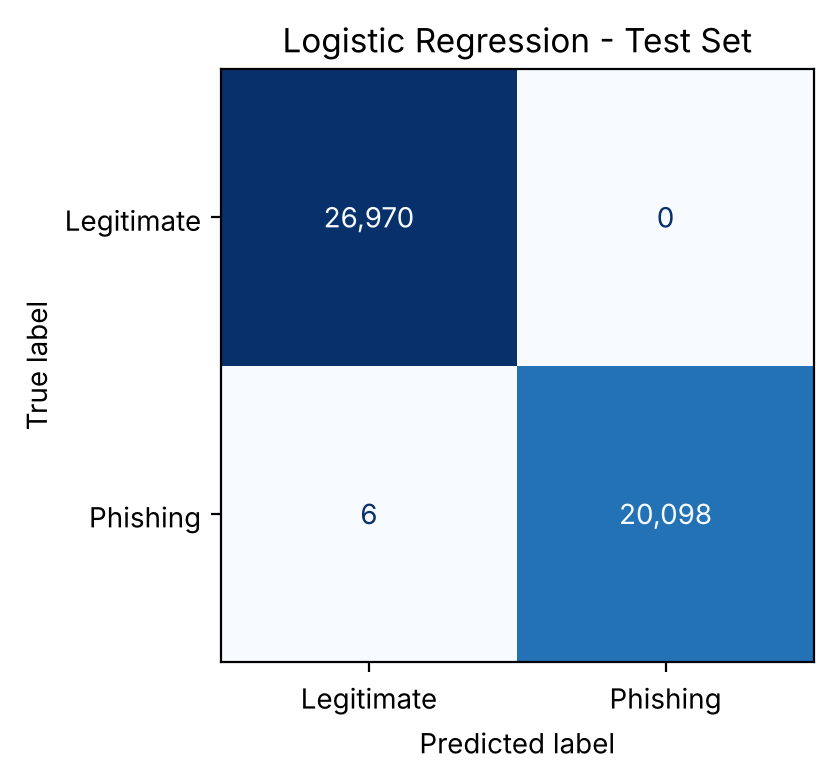

In [7]:
plot_confusion_matrix(y_test, final_model.predict(X_test), f"{MODEL_NAME} - Test Set")

### Feature Weights

Logistic Regression gives each feature a weight. A positive weight pushes a URL towards phishing, and a negative weight pushes it towards legitimate. Because all features are scaled, we can compare the size of the weights. We show the 15 features with the biggest weights.

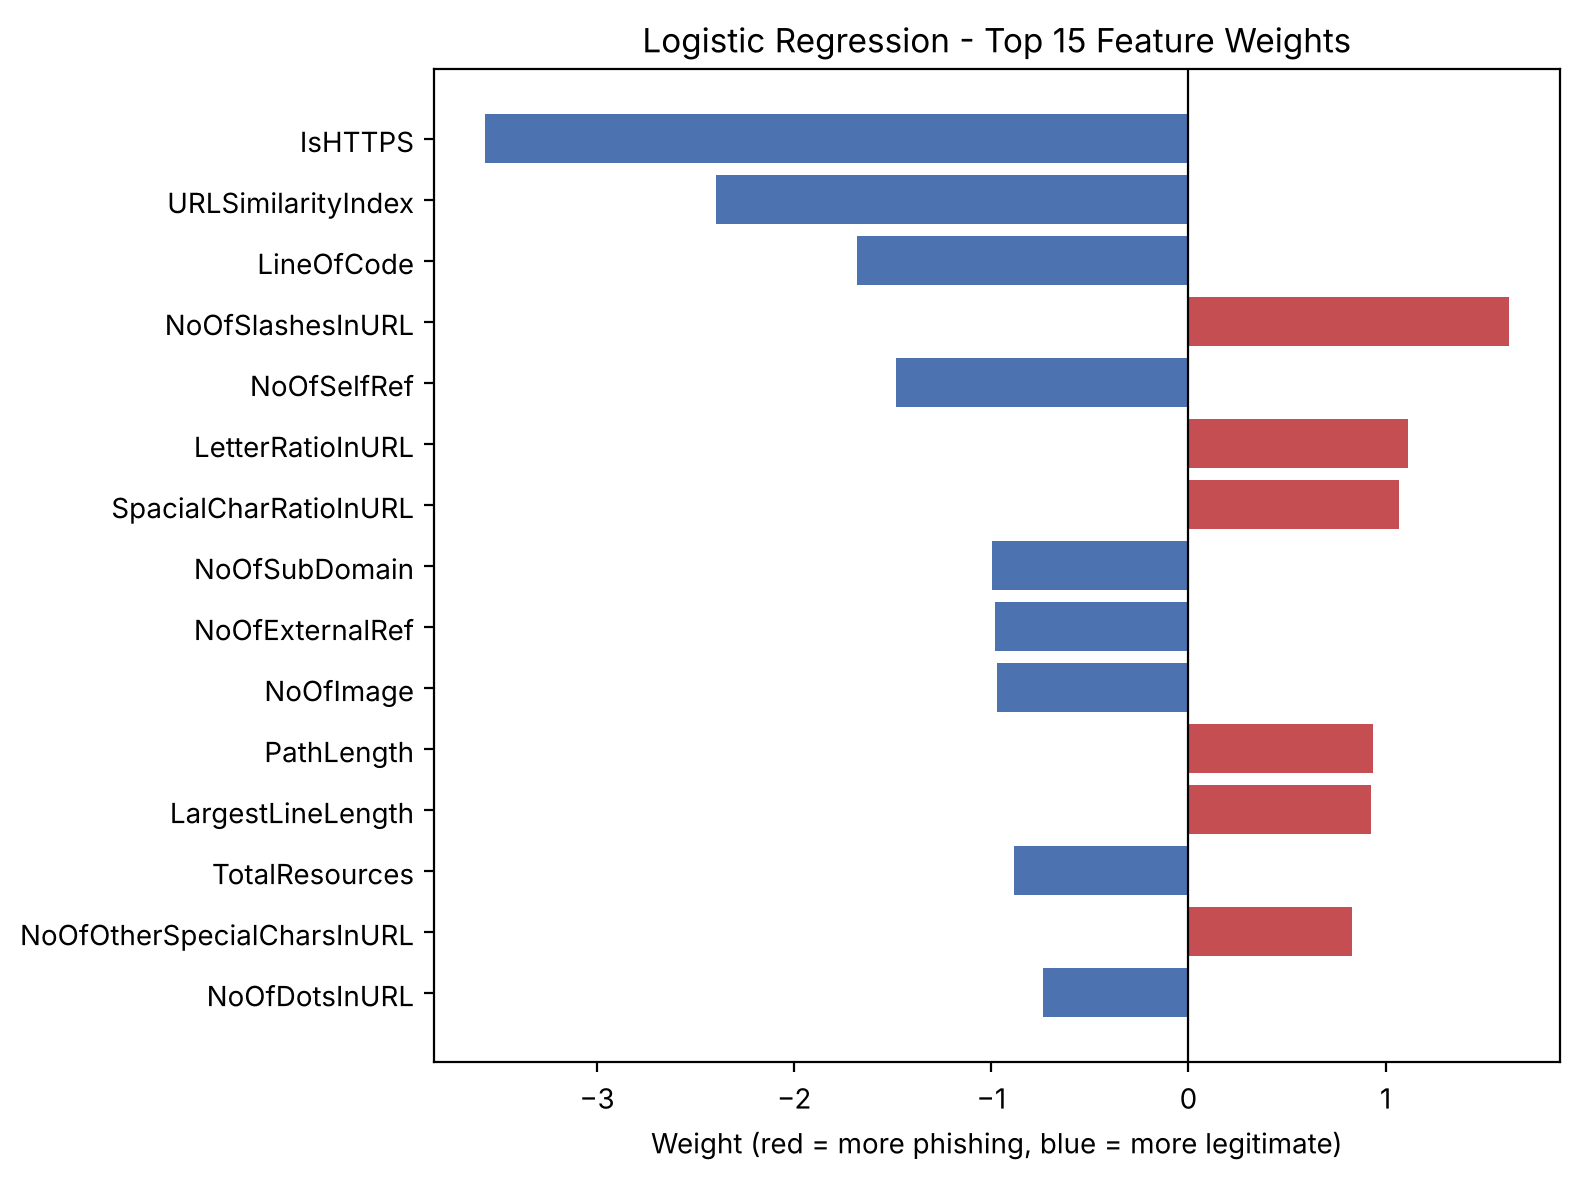

,Weight
IsHTTPS,-3.5697
URLSimilarityIndex,-2.3982
LineOfCode,-1.6831
NoOfSlashesInURL,1.6252
NoOfSelfRef,-1.4809
LetterRatioInURL,1.1128
SpacialCharRatioInURL,1.0690
NoOfSubDomain,-0.9974
NoOfExternalRef,-0.9789
NoOfImage,-0.9697


In [8]:
weights = pd.Series(final_model[-1].coef_[0], index=X_train.columns)
top_features = weights.reindex(weights.abs().sort_values(ascending=False).index).head(15)
colors = ["#C44E52" if w > 0 else "#4C72B0" for w in top_features.values[::-1]]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_features.index[::-1], top_features.values[::-1], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title(f"{MODEL_NAME} - Top 15 Feature Weights")
ax.set_xlabel("Weight (red = more phishing, blue = more legitimate)")
fig.tight_layout()

save_dir = Path("../results/feature_importance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / "logistic_regression_feature_importance.png", dpi=300)
plt.show()

top_features.round(4).to_frame("Weight")

## 4. Feature Set Comparison

We train the same model on two smaller feature sets to answer two questions:

- **Original features only:** do our new features from feature engineering improve the model?
- **Without `URLSimilarityIndex`:** does the model still work well without its strongest feature?

In [9]:
feature_results = {"All features": test_results}

for set_name in ["Original features only", "Without URLSimilarityIndex"]:
    features = feature_sets[set_name]
    set_model = clone(best_model).fit(X_train[features], y_train)
    feature_results[set_name] = evaluate_model(set_model, X_test[features], y_test)

pd.DataFrame(feature_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
All features,0.9999,1.0,0.9997,0.9999,1.0
Original features only,0.9999,1.0,0.9998,0.9999,1.0
Without URLSimilarityIndex,0.9999,1.0,0.9997,0.9999,1.0


## 5. Experiment 2: URL Features Only

Here the model only uses the 18 URL features that we can create from any URL. We train it on PhiUSIIL and test it on both the PhiUSIIL test set and the external dataset. The difference between the two scores shows how well the model works on data from a different source.

In [10]:
X_url_train, X_url_test, X_external, y_url_train, y_url_test, y_external = load_url_experiment()

url_model = clone(best_model).fit(X_url_train, y_url_train)
url_results = {
    "PhiUSIIL test set": evaluate_model(url_model, X_url_test, y_url_test),
    "External dataset": evaluate_model(url_model, X_external, y_external),
}
pd.DataFrame(url_results).T.round(4)

,Accuracy,Precision,Recall,F1,ROC-AUC
PhiUSIIL test set,0.9951,0.9994,0.9892,0.9943,0.9978
External dataset,0.5024,0.5028,0.9928,0.6675,0.4988


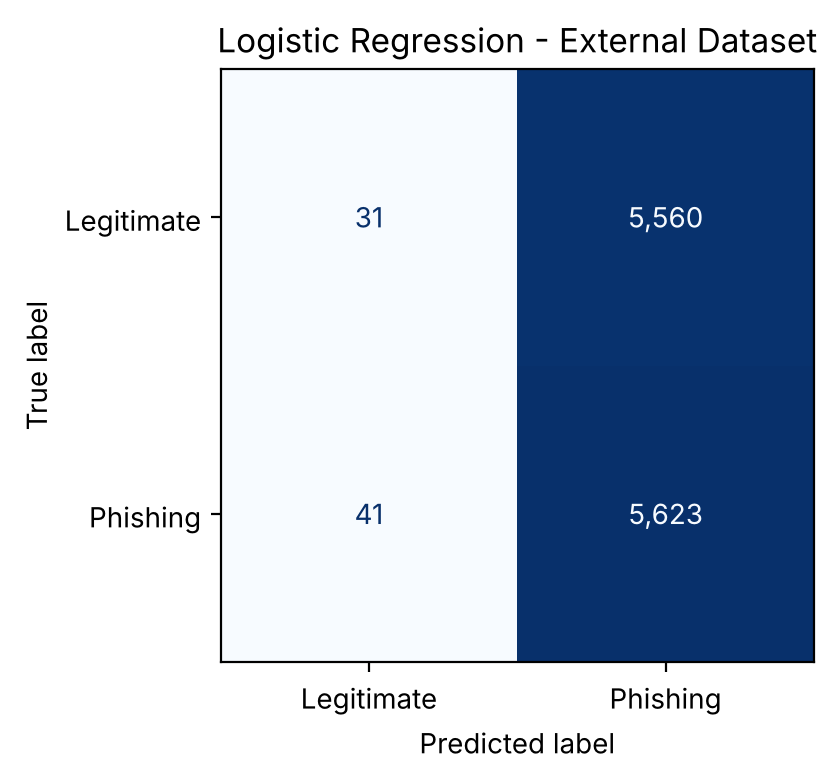

In [11]:
plot_confusion_matrix(y_external, url_model.predict(X_external), f"{MODEL_NAME} - External Dataset")

## 6. Save the Results

We save all results in one table. The comparison notebook will later load the tables of all models.

In [12]:
results = [
    {"Experiment": "Cross-validation", **cv_results["Mean"].to_dict()},
    {"Experiment": "Test set - All features", **test_results, "Train Time (s)": train_time},
    {"Experiment": "Test set - Original features only", **feature_results["Original features only"]},
    {"Experiment": "Test set - Without URLSimilarityIndex", **feature_results["Without URLSimilarityIndex"]},
    {"Experiment": "URL features - PhiUSIIL test set", **url_results["PhiUSIIL test set"]},
    {"Experiment": "URL features - External dataset", **url_results["External dataset"]},
]

save_results(MODEL_NAME, results).round(4)

,Model,Experiment,Accuracy,Precision,Recall,F1,ROC-AUC,Train Time (s)
0,Logistic Regression,Cross-validation,0.9999,1.0000,0.9999,0.9999,1.0000,NaN
1,Logistic Regression,Test set - All features,0.9999,1.0000,0.9997,0.9999,1.0000,0.5311
2,Logistic Regression,Test set - Original features only,0.9999,1.0000,0.9998,0.9999,1.0000,NaN
3,Logistic Regression,Test set - Without URLSimilarityIndex,0.9999,1.0000,0.9997,0.9999,1.0000,NaN
4,Logistic Regression,URL features - PhiUSIIL test set,0.9951,0.9994,0.9892,0.9943,0.9978,NaN
5,Logistic Regression,URL features - External dataset,0.5024,0.5028,0.9928,0.6675,0.4988,NaN


## 7. Findings

- **Test score:** Logistic Regression made only **6 mistakes out of 47,074 test URLs** (accuracy 99.99%). It never called a legitimate URL phishing (precision 100%), and it missed 6 of the 20,104 phishing URLs (recall 99.97%).
- **Stability:** The 5-fold cross-validation scores were almost the same in every fold (standard deviation 0.0001 or less), so the result is stable.
- **Best settings:** `C = 10`, the largest value we tried. The model worked best when it was allowed to follow the training data closely, and it still did well on the test set, so it did not overfit.
- **Feature weights:** The biggest weights belong to `IsHTTPS`, `URLSimilarityIndex` and `LineOfCode`. Their weights are negative, so HTTPS, a high similarity score and a longer page all push a URL towards legitimate. `NoOfSlashesInURL` and `LetterRatioInURL` have positive weights, so they push a URL towards phishing. Our new features `PathLength`, `TotalResources` and `NoOfSlashesInURL` are in the top 15.
- **New features:** Using only the original features gave the same score, so on this dataset the original features are already enough.
- **Without `URLSimilarityIndex`:** The score did not change (still 6 mistakes). Logistic Regression uses many features together, so it does not depend on one feature.
- **Simple model, strong result:** Even this simple linear model is almost perfect. This shows the PhiUSIIL features separate phishing and legitimate URLs very clearly.
- **Experiment 2 (URL features only):** The model scored 99.5% on the PhiUSIIL test set but only **50.2% on the external dataset**. It called 5,560 of the 5,591 legitimate external URLs phishing (recall 99.3%, precision 50.3%). This is the same distribution shift seen in all models, and we will fix it by training on both datasets together.